# **Credit Portfolio Segmentation and Risk Pattern Analysis**
This notebook applies the workflow of the *Airline Customer Segmentation* notebook (clean → engineer features → standardize → K-Means → PCA/radar profiling → name segments) to a consumer loan portfolio (`portfolio.xlsx`, 721 loans issued 2015-12). The airline **LRFMC** model is replaced by a credit-risk equivalent, and a final section adds **risk pattern analysis** (default rates by segment).

| Airline (LRFMC) | Credit portfolio equivalent |
|---|---|
| Customer | Loan / borrower |
| **L**ength of membership | **E** – Employment length (stability) |
| **R**ecency | **D** – Debt-to-income (`dti_n`, current obligation burden) |
| **F**requency | **S** – Credit score (`fico_n`) |
| **M**onetary | **I** – Income (`revenue`) and **A** – Loan amount (`loan_amnt`) |
| Discount coefficient | **T** – Loan-to-income ratio (engineered leverage) |

Key difference: in the airline data, behaviour (R, F, M) was the only signal. Here we also have the outcome label `Default`, which we deliberately **keep out of the clustering** and use afterwards to check whether segments differ in risk.

# **Import** **Libraries**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# **Import** **Dataset**

In [2]:
data = pd.read_excel('portfolio.xlsx')   # place portfolio.xlsx next to this notebook
print(data.shape)
data.head()

(721, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,2015-12-01,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,2015-12-01,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,2015-12-01,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,2015-12-01,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68476668,2015-12-01,180000.0,14.67,20000,682.0,1,10+ years,debt_consolidation,MORTGAGE,MN,550xx,0,Debt consolidation,NaN


# **Data** **Understanding**

In [3]:
data.dtypes

id                           int64
issue_d             datetime64[us]
revenue                    float64
dti_n                      float64
loan_amnt                    int64
fico_n                     float64
experience_c                 int64
emp_length                     str
purpose                        str
home_ownership_n               str
addr_state                     str
zip_code                       str
Default                      int64
title                          str
desc                           str
dtype: object

In [4]:
#duplicate value checking
print('duplicate rows:', data.duplicated().sum(), '| duplicate ids:', data['id'].duplicated().sum())

duplicate rows: 0 | duplicate ids: 0


In [5]:
#null value checking
data.isnull().sum()

id                    0
issue_d               0
revenue               0
dti_n                 0
loan_amnt             0
fico_n                0
experience_c          0
emp_length            0
purpose               0
home_ownership_n      0
addr_state            0
zip_code              0
Default               0
title                24
desc                720
dtype: int64

In [6]:
#numerical columns
nums = data.select_dtypes(include=[np.number]).columns
#categorical columns
cats = data.select_dtypes(exclude=[np.number]).columns
print(list(nums)); print(list(cats))

['id', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'Default']
['issue_d', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'title', 'desc']


In [7]:
data[nums].describe().T

,count,mean,std,min,25%,50%,75%,max
id,721.0,6.816635e+07,3.593594e+06,361774.0,68375498.00,68466830.00,68546047.00,68617057.00
revenue,721.0,8.727103e+04,4.769814e+04,13000.0,55000.00,78000.00,107000.00,650000.00
dti_n,721.0,1.892673e+01,8.192178e+00,0.0,13.03,18.51,24.86,38.65
loan_amnt,721.0,1.563204e+04,8.969617e+03,1000.0,8275.00,14000.00,22000.00,35000.00
fico_n,721.0,7.032836e+02,3.407472e+01,662.0,677.00,697.00,722.00,847.50
experience_c,721.0,1.000000e+00,0.000000e+00,1.0,1.00,1.00,1.00,1.00
Default,721.0,1.303745e-01,3.369487e-01,0.0,0.00,0.00,0.00,1.00


* `experience_c` is constant (always 1), so it carries no information.
* `Default` is binary: it is the risk outcome, not a clustering feature.
* `revenue` (annual income) is strongly right-skewed (max 650,000 vs median 78,000), so it will need a log transform.

In [8]:
data[cats].describe().T

,count,mean,min,25%,50%,75%,max
issue_d,721,2015-12-01 00:00:00,2015-12-01 00:00:00,2015-12-01 00:00:00,2015-12-01 00:00:00,2015-12-01 00:00:00,2015-12-01 00:00:00


In [9]:
for c in ['home_ownership_n','purpose','emp_length']:
    print(data[c].value_counts(normalize=True).round(3).head(12), '\n')

home_ownership_n
MORTGAGE    1.0
Name: proportion, dtype: float64 

purpose
debt_consolidation    0.567
credit_card           0.241
home_improvement      0.093
other                 0.046
major_purchase        0.015
car                   0.014
small_business        0.010
house                 0.006
vacation              0.004
medical               0.004
Name: proportion, dtype: float64 

emp_length
10+ years    0.417
< 1 year     0.089
2 years      0.076
3 years      0.072
5 years      0.057
8 years      0.054
NI           0.051
1 year       0.049
4 years      0.046
9 years      0.031
6 years      0.031
7 years      0.028
Name: proportion, dtype: float64 



* `home_ownership_n` has a single value (MORTGAGE) → drop.
* `issue_d` is a single date → drop (so there is no L/R time dimension as in the airline data).
* `desc` is 99.9% missing and `title` duplicates `purpose` → drop; `id`, `addr_state` (46 values) and `zip_code` (373 values on 721 rows) are identifiers/high-cardinality → drop, as the airline notebook did with `WORK_CITY` etc.
* `emp_length` has the text value `NI` (no information) for ~5% of loans.

# **Univariate**

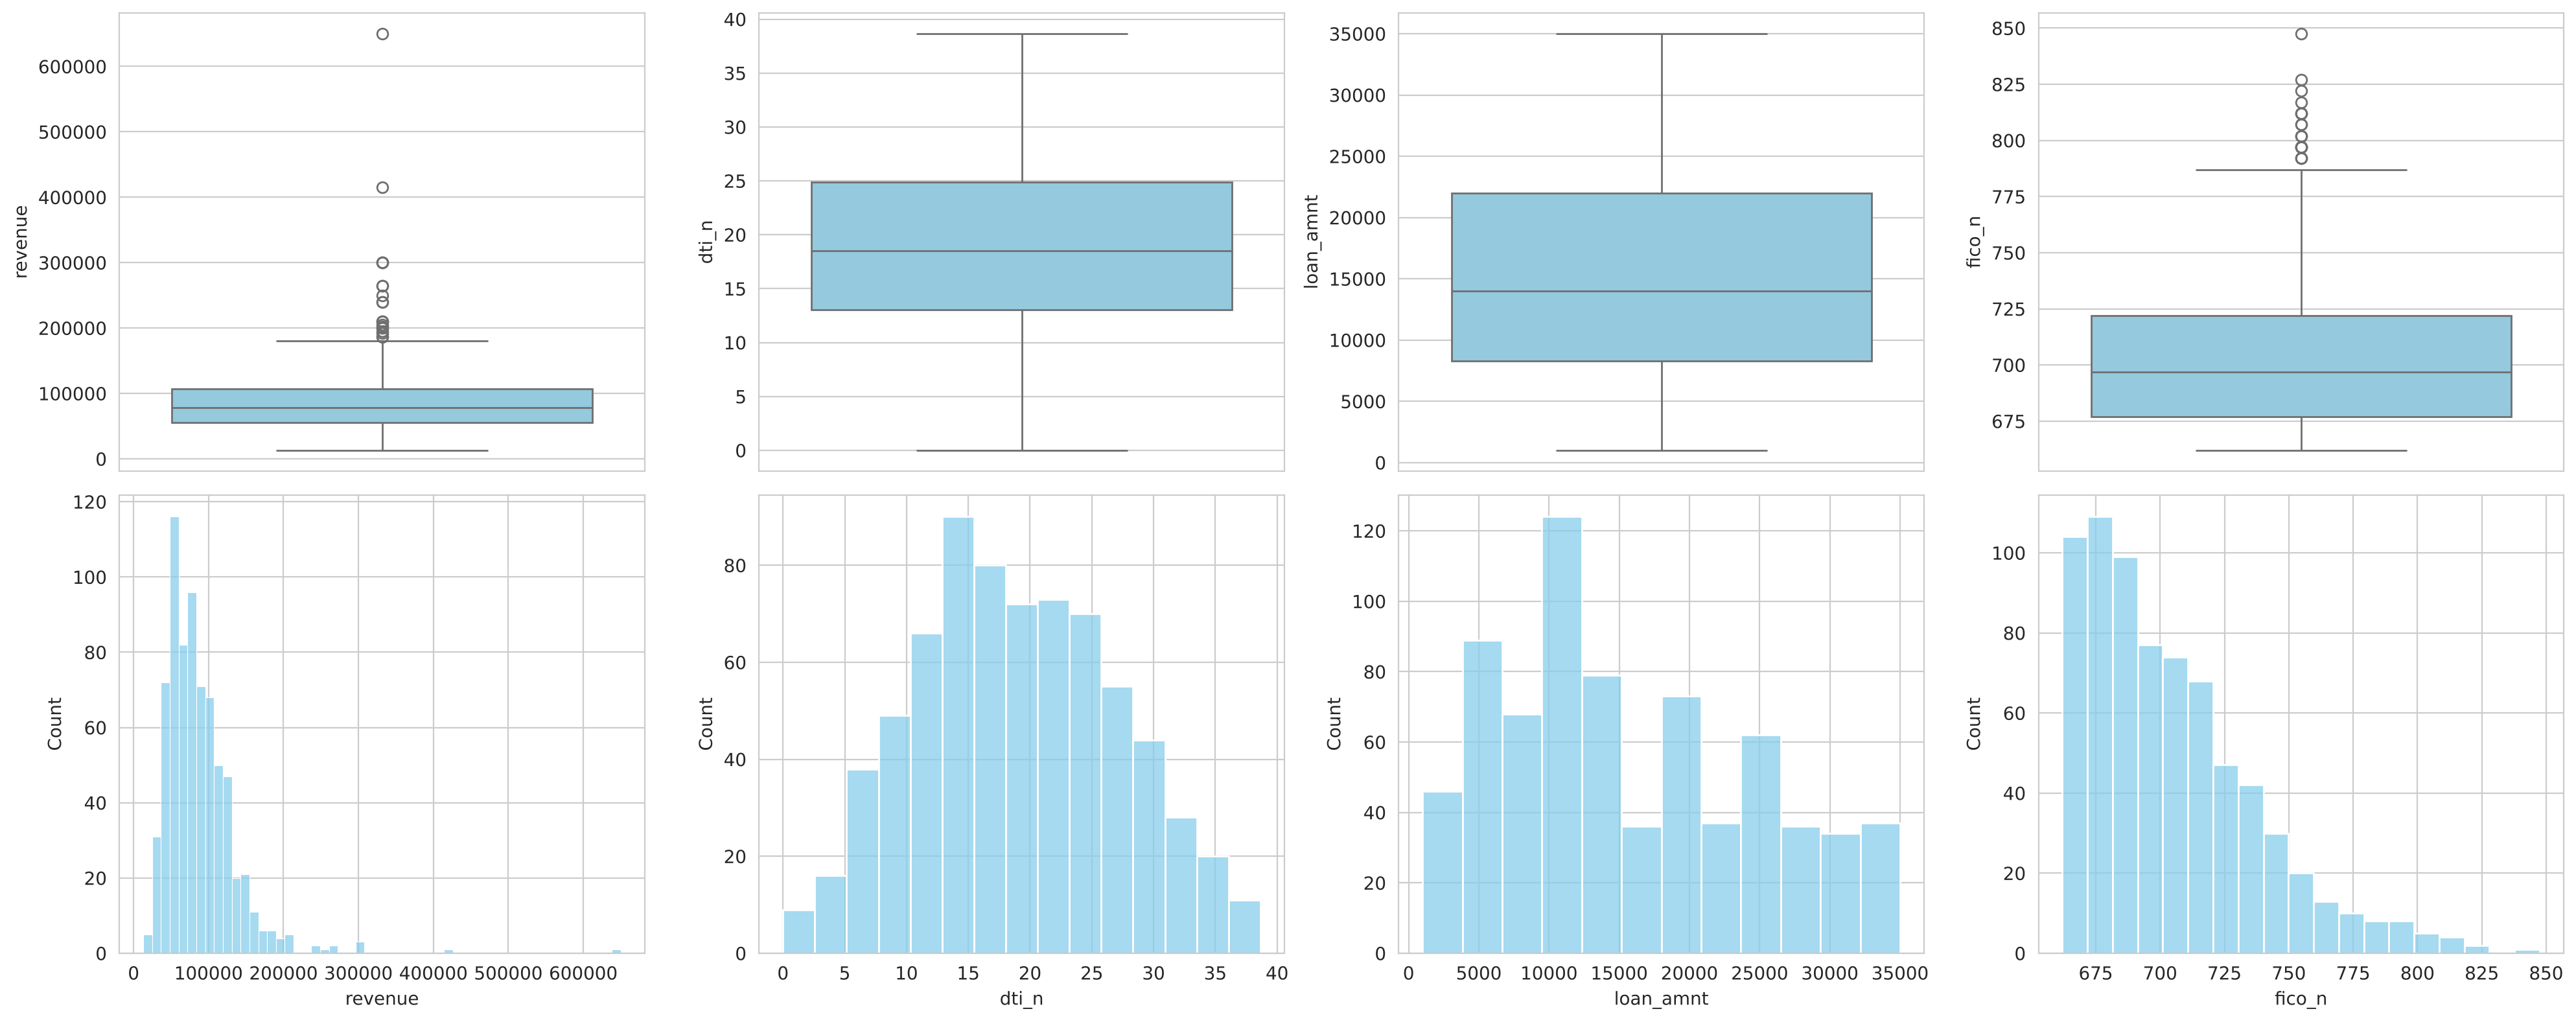

In [10]:
features = ['revenue','dti_n','loan_amnt','fico_n']
fig, ax = plt.subplots(2, 4, figsize=(20,8))
for i,f in enumerate(features):
    sns.boxplot(y=data[f], color='skyblue', ax=ax[0,i])
    sns.histplot(x=data[f], color='skyblue', ax=ax[1,i])
plt.tight_layout()

* `revenue` and `fico_n` are positively skewed with extreme high values; `dti_n` and `loan_amnt` are roughly symmetric/bounded.
* A handful of `dti_n = 0` values exist (no stated debt), which are plausible and kept.

# **Multivariate**

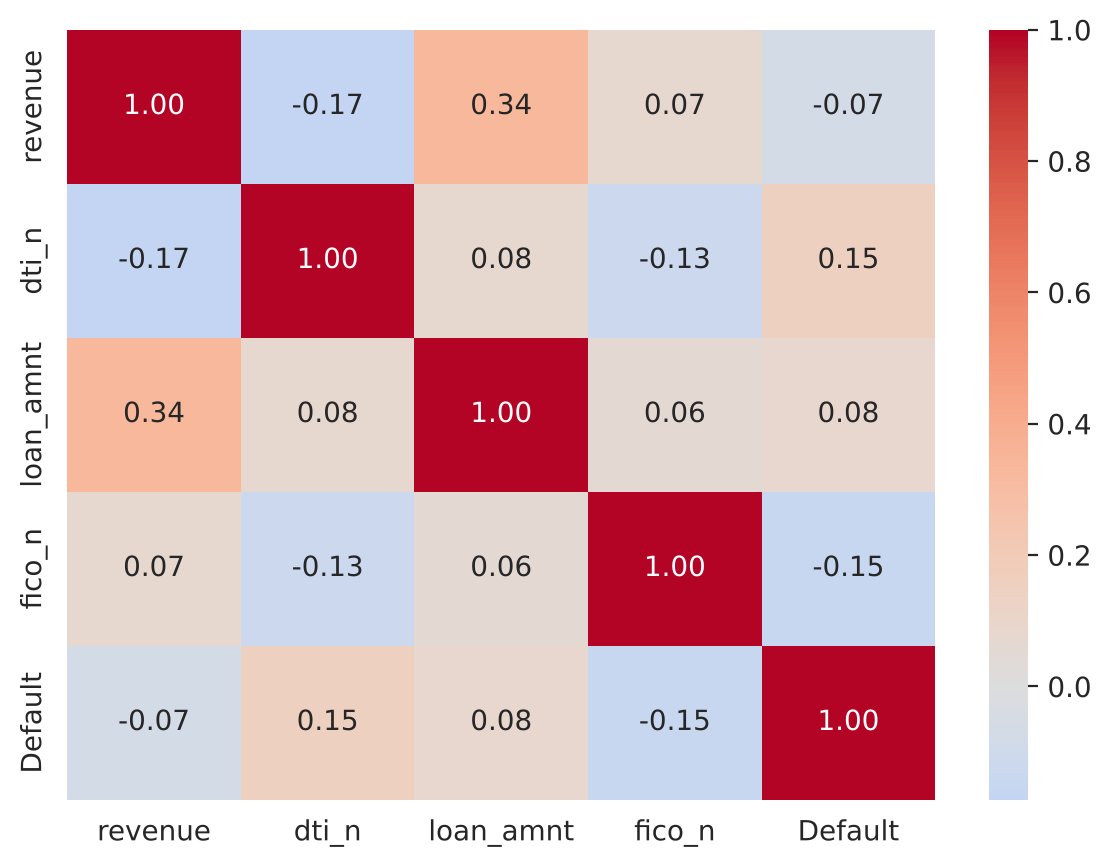

In [11]:
plt.figure(figsize=(7,5))
sns.heatmap(data[['revenue','dti_n','loan_amnt','fico_n','Default']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

# **Data** **Cleaning**

In [12]:
percent_missing = data.isnull().sum() * 100 / len(data)
pd.DataFrame({'percent_missing': percent_missing})

,percent_missing
id,0.000000
issue_d,0.000000
revenue,0.000000
dti_n,0.000000
loan_amnt,0.000000
fico_n,0.000000
experience_c,0.000000
emp_length,0.000000
purpose,0.000000
home_ownership_n,0.000000


In [13]:
# Drop constant / identifier / free-text / high-cardinality columns
data = data.drop(['id','issue_d','experience_c','home_ownership_n','addr_state','zip_code','title','desc'], axis=1)
data.columns.tolist()

['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'emp_length', 'purpose', 'Default']

# **Feature** **Engineering**

In [14]:
# emp_length text -> years. '< 1 year' = 0, '10+ years' = 10, 'NI' (no info) = missing -> median
def emp_to_years(s):
    if s == 'NI': return np.nan
    if s.startswith('<'): return 0.0
    return float(s.replace('+','').split()[0])

data['emp_years'] = data['emp_length'].apply(emp_to_years)
print('NI count:', data['emp_years'].isnull().sum())
data['emp_years'] = data['emp_years'].fillna(data['emp_years'].median())

# Loan-to-income: leverage of the new loan relative to income
data['lti'] = data['loan_amnt'] / data['revenue']
data[['emp_length','emp_years','lti']].head()

NI count: 37


,emp_length,emp_years,lti
0,10+ years,10.0,0.065455
1,10+ years,10.0,0.380000
2,10+ years,10.0,0.281690
3,3 years,3.0,0.099585
4,10+ years,10.0,0.111111


# **Outliers** **Handling**

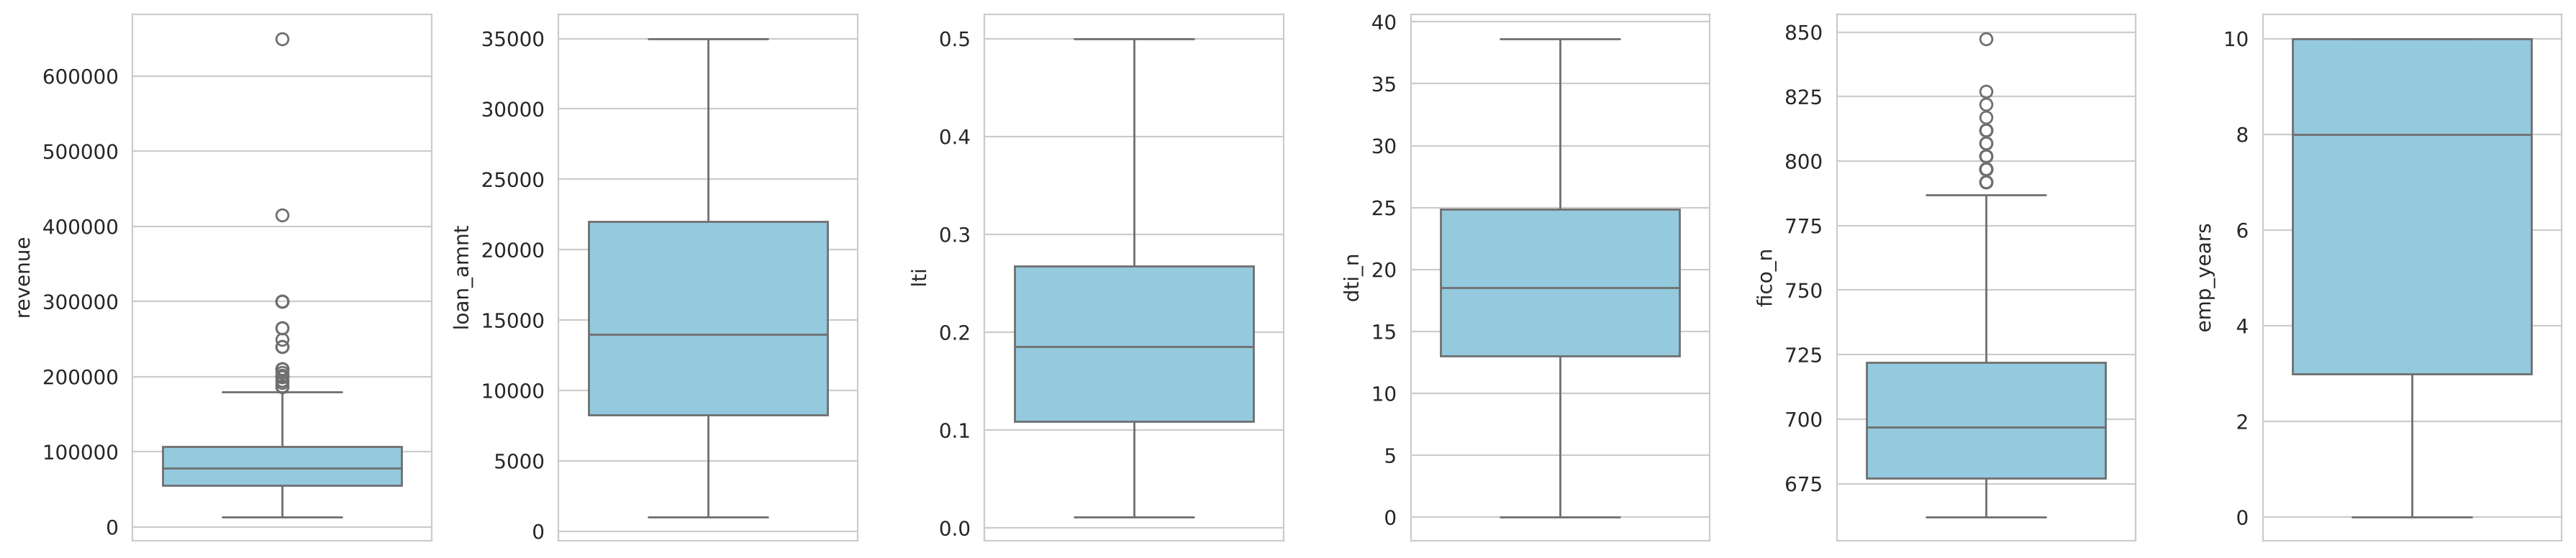

In [15]:
plt.figure(figsize=(18,4))
for i,f in enumerate(['revenue','loan_amnt','lti','dti_n','fico_n','emp_years']):
    plt.subplot(1,6,i+1); sns.boxplot(y=data[f], color='skyblue')
plt.tight_layout(); plt.show()

* As in the airline notebook, natural variation is kept. Only the extreme `revenue` values are treated: the few incomes above 300,000 are not removed (only 2 rows, both non-defaults) but a **log transform** is applied to `revenue`, `loan_amnt` and `lti` so they do not dominate the K-Means distance.
* Age filtering from the airline notebook has no equivalent here.

In [16]:
print((data['revenue'] > 300_000).sum(), 'loans with income > 300k')
data.shape

2 loans with income > 300k


(721, 9)

# **Feature** **Selection**

The airline notebook used LRFMC. For credit risk the analogous drivers are:
* **I**ncome – `revenue` (log)
* **A**mount – `loan_amnt` (log)
* **T** – loan-to-income `lti` (log): leverage of the new loan
* **D**TI – `dti_n`: existing debt burden
* **S**core – `fico_n`: bureau credit score (higher = better)
* **E**mployment – `emp_years`: job stability

`Default` is excluded from the features and used afterwards to validate/profile the segments.

In [17]:
dff = pd.DataFrame({
    'I': np.log1p(data['revenue']),
    'A': np.log1p(data['loan_amnt']),
    'T': np.log1p(data['lti']),
    'D': data['dti_n'],
    'S': data['fico_n'],
    'E': data['emp_years'],
})
dff.head()

,I,A,T,D,S,E
0,10.915107,8.188967,0.063402,5.91,677.0,10.0
1,11.082158,10.114599,0.322083,16.06,717.0,10.0
2,11.170449,9.903538,0.248180,13.85,697.0,10.0
3,11.556311,9.249657,0.094933,25.37,697.0,3.0
4,12.100718,9.903538,0.105361,14.67,682.0,10.0


# **Data** **Standardization**

In [18]:
sc = StandardScaler()
data_std = pd.DataFrame(sc.fit_transform(dff), columns=dff.columns)
data_std.head()

,I,A,T,D,S,E
0,-0.749609,-1.809023,-1.247161,-1.590024,-0.771888,0.933716
1,-0.391178,0.947984,1.602015,-0.350178,0.402817,0.933716
2,-0.201737,0.645799,0.788023,-0.620134,-0.184536,0.933716
3,0.626180,-0.290389,-0.899865,0.787061,-0.184536,-0.963411
4,1.794279,0.645799,-0.785016,-0.519969,-0.625050,0.933716


# **K**-**Means** **Clustering**

To choose the number of clusters we check inertia (elbow) and, in addition to the airline notebook, the silhouette score.

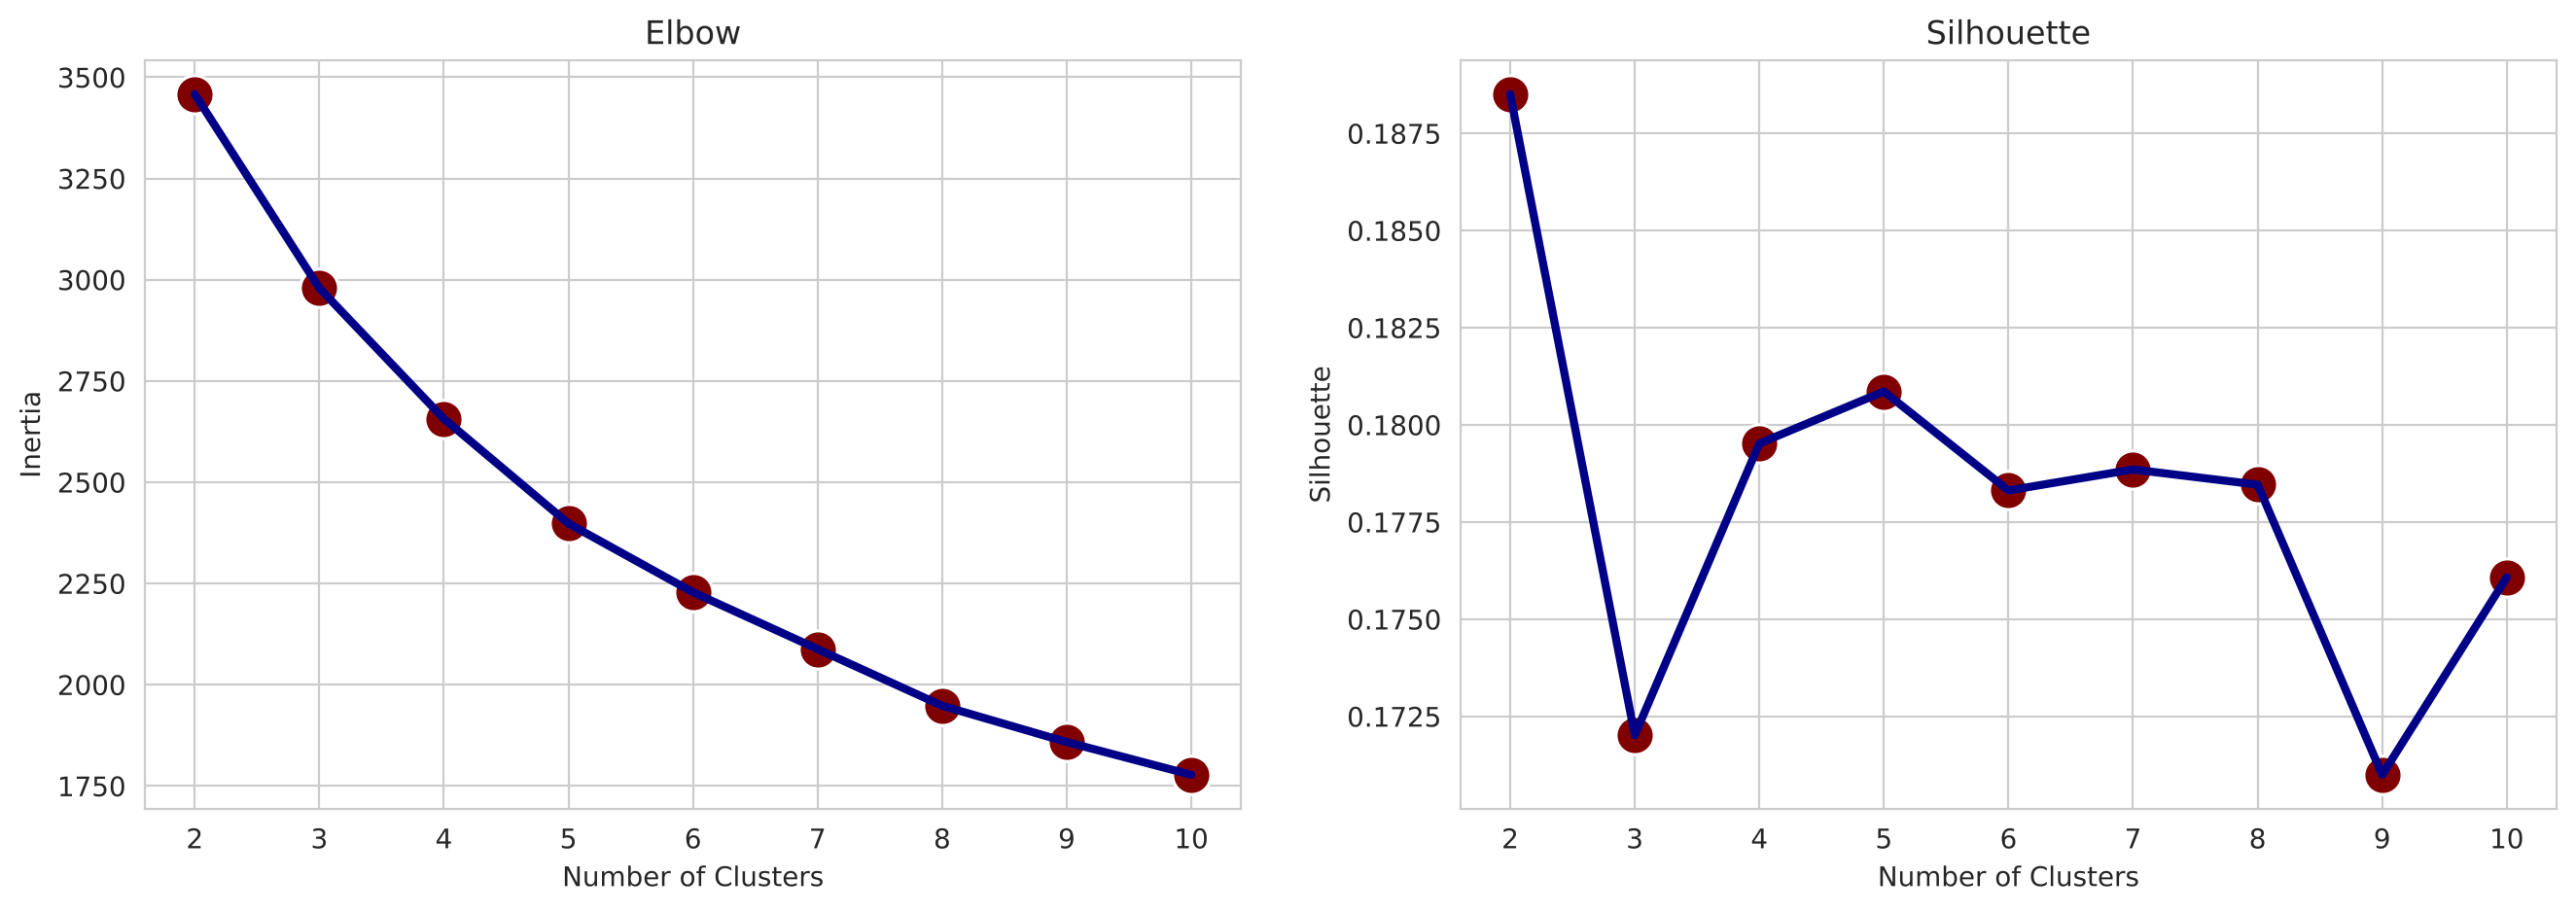

    k   inertia  silhouette
0   2  3458.252       0.189
1   3  2979.534       0.172
2   4  2656.839       0.180
3   5  2398.173       0.181
4   6  2228.338       0.178
5   7  2088.097       0.179
6   8  1948.088       0.178
7   9  1858.513       0.171
8  10  1777.605       0.176


In [19]:
inertia, sil = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(data_std)
    inertia.append(km.inertia_); sil.append(silhouette_score(data_std, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(16,5))
sns.lineplot(x=list(ks), y=inertia, color='#000087', linewidth=3, ax=ax[0])
sns.scatterplot(x=list(ks), y=inertia, s=200, color='#800000', ax=ax[0])
ax[0].set(xlabel='Number of Clusters', ylabel='Inertia', title='Elbow'); ax[0].set_xticks(list(ks))
sns.lineplot(x=list(ks), y=sil, color='#000087', linewidth=3, ax=ax[1])
sns.scatterplot(x=list(ks), y=sil, s=200, color='#800000', ax=ax[1])
ax[1].set(xlabel='Number of Clusters', ylabel='Silhouette', title='Silhouette'); ax[1].set_xticks(list(ks))
plt.show()
print(pd.DataFrame({'k':list(ks),'inertia':inertia,'silhouette':sil}).round(3))

The elbow is gradual and silhouette scores are low (~0.18) and flat across k, which is typical for borrower data where profiles overlap on a continuum rather than forming separated blobs. As in the airline notebook, we therefore weigh **business interpretability**: we compare k = 4, 5 and 6.

#### 4 Clusters

In [20]:
data_std_4 = data_std.copy()
kmeans_4 = KMeans(n_clusters=4, random_state=0, n_init=10).fit(data_std_4)
data_std_4['clusters'] = kmeans_4.labels_
print('sizes:', np.bincount(kmeans_4.labels_), '| silhouette:', round(silhouette_score(data_std, kmeans_4.labels_),3))
radar_plot_4 = data_std_4.groupby('clusters').agg('median').reset_index()
radar_plot_4

sizes: [207 103 236 175] | silhouette: 0.18


,clusters,I,A,T,D,S,E
0,0,0.924305,0.413126,-0.423863,-0.555394,-0.331374,0.120661
1,1,-0.084140,-0.210091,-0.247632,-0.673881,1.577523,0.391680
2,2,-0.232172,0.715650,1.063440,0.515883,-0.331374,0.391680
3,3,-0.562918,-1.077812,-0.941320,0.281350,-0.625050,0.391680


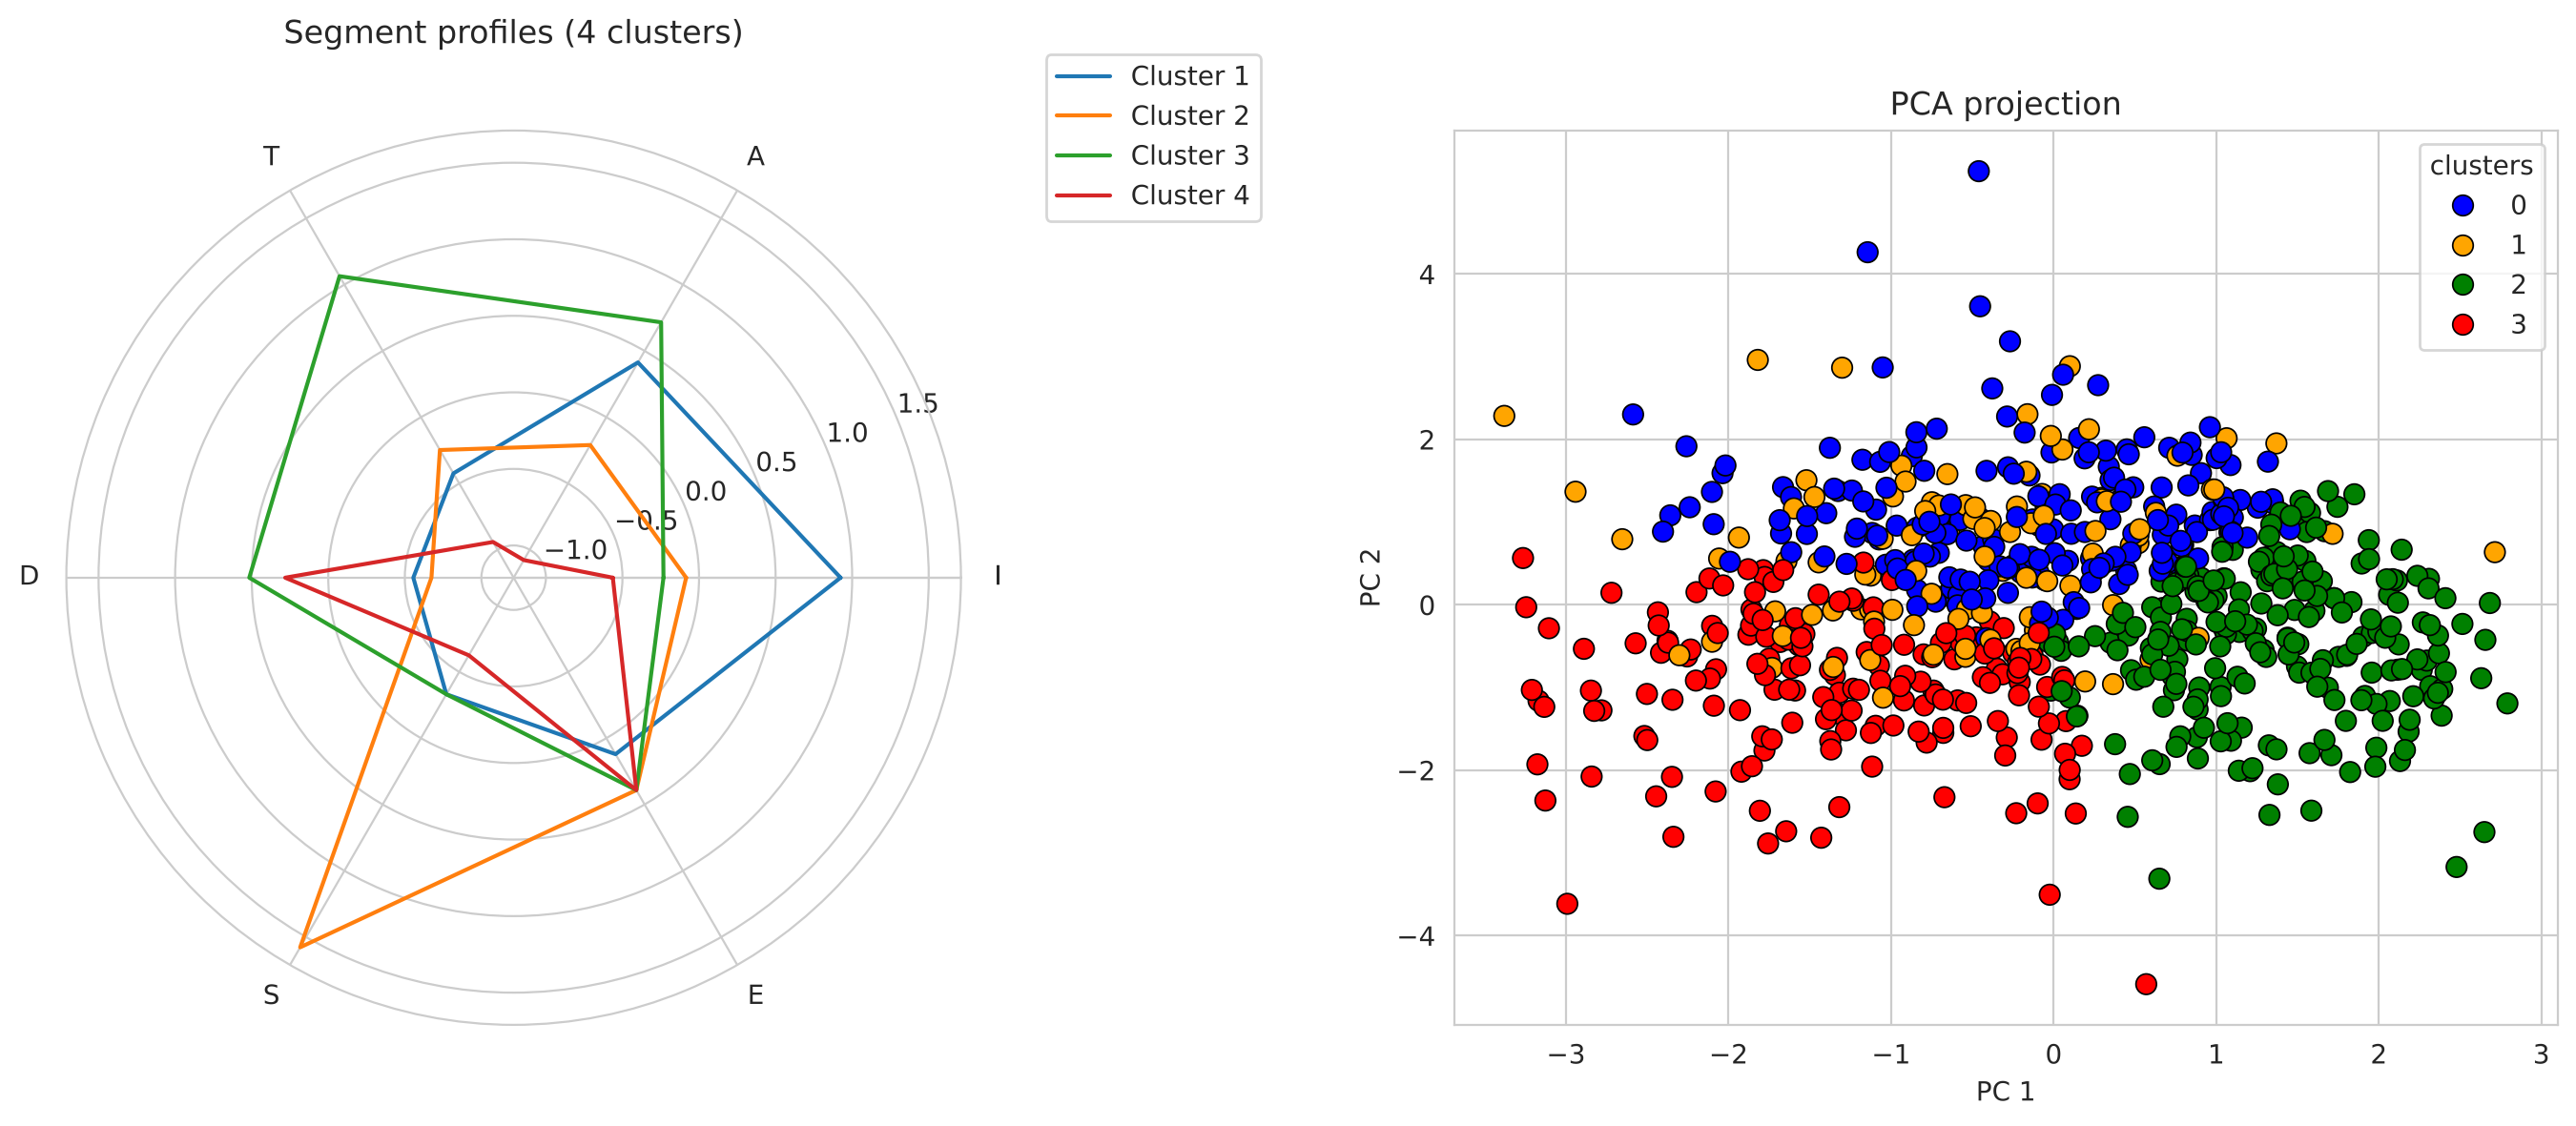

In [21]:
category = ['I','A','T','D','S','E']
label_loc = np.linspace(0, 2*np.pi, len(category)+1)
fig = plt.figure(figsize=(14,6))
ax1 = fig.add_subplot(121, polar=True)
for i in range(4):
    vals = radar_plot_4.loc[i, category].tolist(); vals.append(vals[0])
    ax1.plot(label_loc, vals, label=f'Cluster {i+1}')
ax1.set_thetagrids(np.degrees(label_loc), labels=category+[category[0]])
ax1.set_title('Segment profiles (4 clusters)', y=1.08); ax1.legend(loc='upper right', bbox_to_anchor=(1.35,1.1))

pcs = PCA(n_components=2).fit_transform(data_std_4.drop(columns='clusters'))
ax2 = fig.add_subplot(122)
sns.scatterplot(x=pcs[:,0], y=pcs[:,1], hue=data_std_4['clusters'], palette=['blue','orange','green','red'], edgecolor='black', s=60, ax=ax2)
ax2.set(xlabel='PC 1', ylabel='PC 2', title='PCA projection')
plt.tight_layout(); plt.show()

#### 5 Clusters

In [22]:
data_std_5 = data_std.copy()
kmeans_5 = KMeans(n_clusters=5, random_state=0, n_init=10).fit(data_std_5)
data_std_5['clusters'] = kmeans_5.labels_
print('sizes:', np.bincount(kmeans_5.labels_), '| silhouette:', round(silhouette_score(data_std, kmeans_5.labels_),3))
radar_plot_5 = data_std_5.groupby('clusters').agg('median').reset_index()
radar_plot_5

sizes: [160 148 170  98 145] | silhouette: 0.181


,clusters,I,A,T,D,S,E
0,0,-0.562918,-1.202368,-0.987118,0.286847,-0.625050,0.391680
1,1,1.011893,0.233936,-0.684579,-0.741676,-0.404793,0.662698
2,2,-0.084140,0.841991,0.924582,0.515272,-0.184536,0.933716
3,3,-0.069931,-0.210091,-0.372534,-0.673271,1.577523,0.391680
4,4,-0.232172,0.622343,0.607632,0.165306,-0.331374,-1.234430


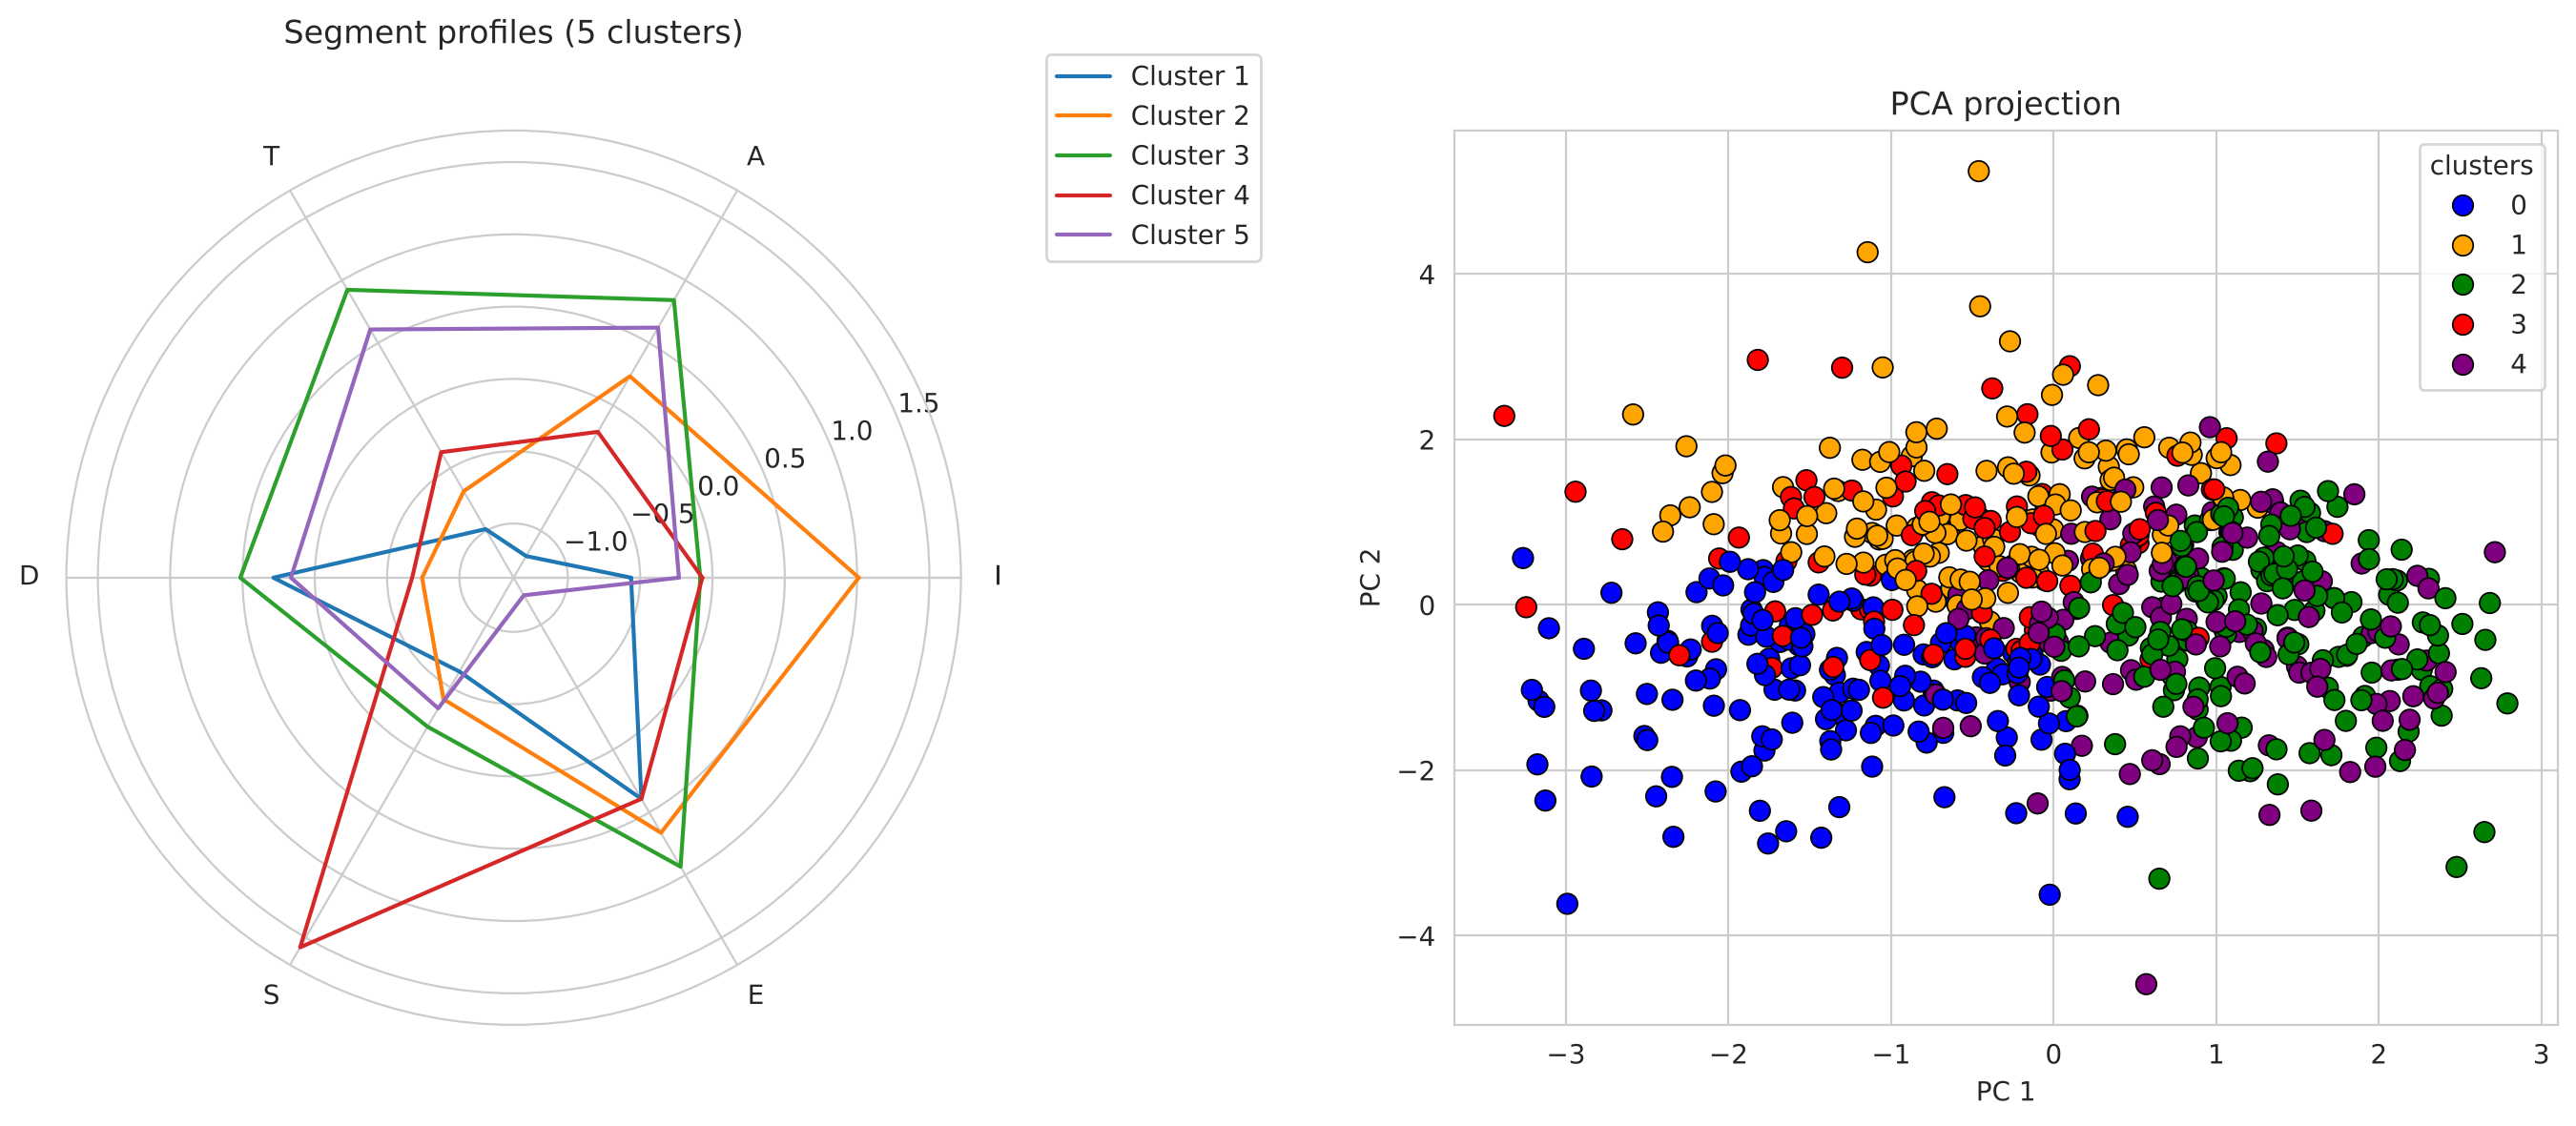

In [23]:
category = ['I','A','T','D','S','E']
label_loc = np.linspace(0, 2*np.pi, len(category)+1)
fig = plt.figure(figsize=(14,6))
ax1 = fig.add_subplot(121, polar=True)
for i in range(5):
    vals = radar_plot_5.loc[i, category].tolist(); vals.append(vals[0])
    ax1.plot(label_loc, vals, label=f'Cluster {i+1}')
ax1.set_thetagrids(np.degrees(label_loc), labels=category+[category[0]])
ax1.set_title('Segment profiles (5 clusters)', y=1.08); ax1.legend(loc='upper right', bbox_to_anchor=(1.35,1.1))

pcs = PCA(n_components=2).fit_transform(data_std_5.drop(columns='clusters'))
ax2 = fig.add_subplot(122)
sns.scatterplot(x=pcs[:,0], y=pcs[:,1], hue=data_std_5['clusters'], palette=['blue','orange','green','red','purple'], edgecolor='black', s=60, ax=ax2)
ax2.set(xlabel='PC 1', ylabel='PC 2', title='PCA projection')
plt.tight_layout(); plt.show()

#### 6 Clusters

In [24]:
data_std_6 = data_std.copy()
kmeans_6 = KMeans(n_clusters=6, random_state=0, n_init=10).fit(data_std_6)
data_std_6['clusters'] = kmeans_6.labels_
print('sizes:', np.bincount(kmeans_6.labels_), '| silhouette:', round(silhouette_score(data_std, kmeans_6.labels_),3))
radar_plot_6 = data_std_6.groupby('clusters').agg('median').reset_index()
radar_plot_6

sizes: [128 124  95 170  89 115] | silhouette: 0.178


,clusters,I,A,T,D,S,E
0,0,-0.730279,-1.338801,-1.063872,0.158587,-0.771888,0.391680
1,1,0.906274,0.135163,-0.684579,-0.559669,-0.478212,0.933716
2,2,-0.749609,0.326333,1.049655,0.430376,-0.478212,-1.234430
3,3,-0.142335,0.835740,0.906202,0.526266,-0.184536,0.933716
4,4,-0.232172,-0.346537,-0.310750,-0.552951,1.577523,0.933716
5,5,0.737612,0.622343,-0.202767,-0.518748,-0.037697,-1.234430


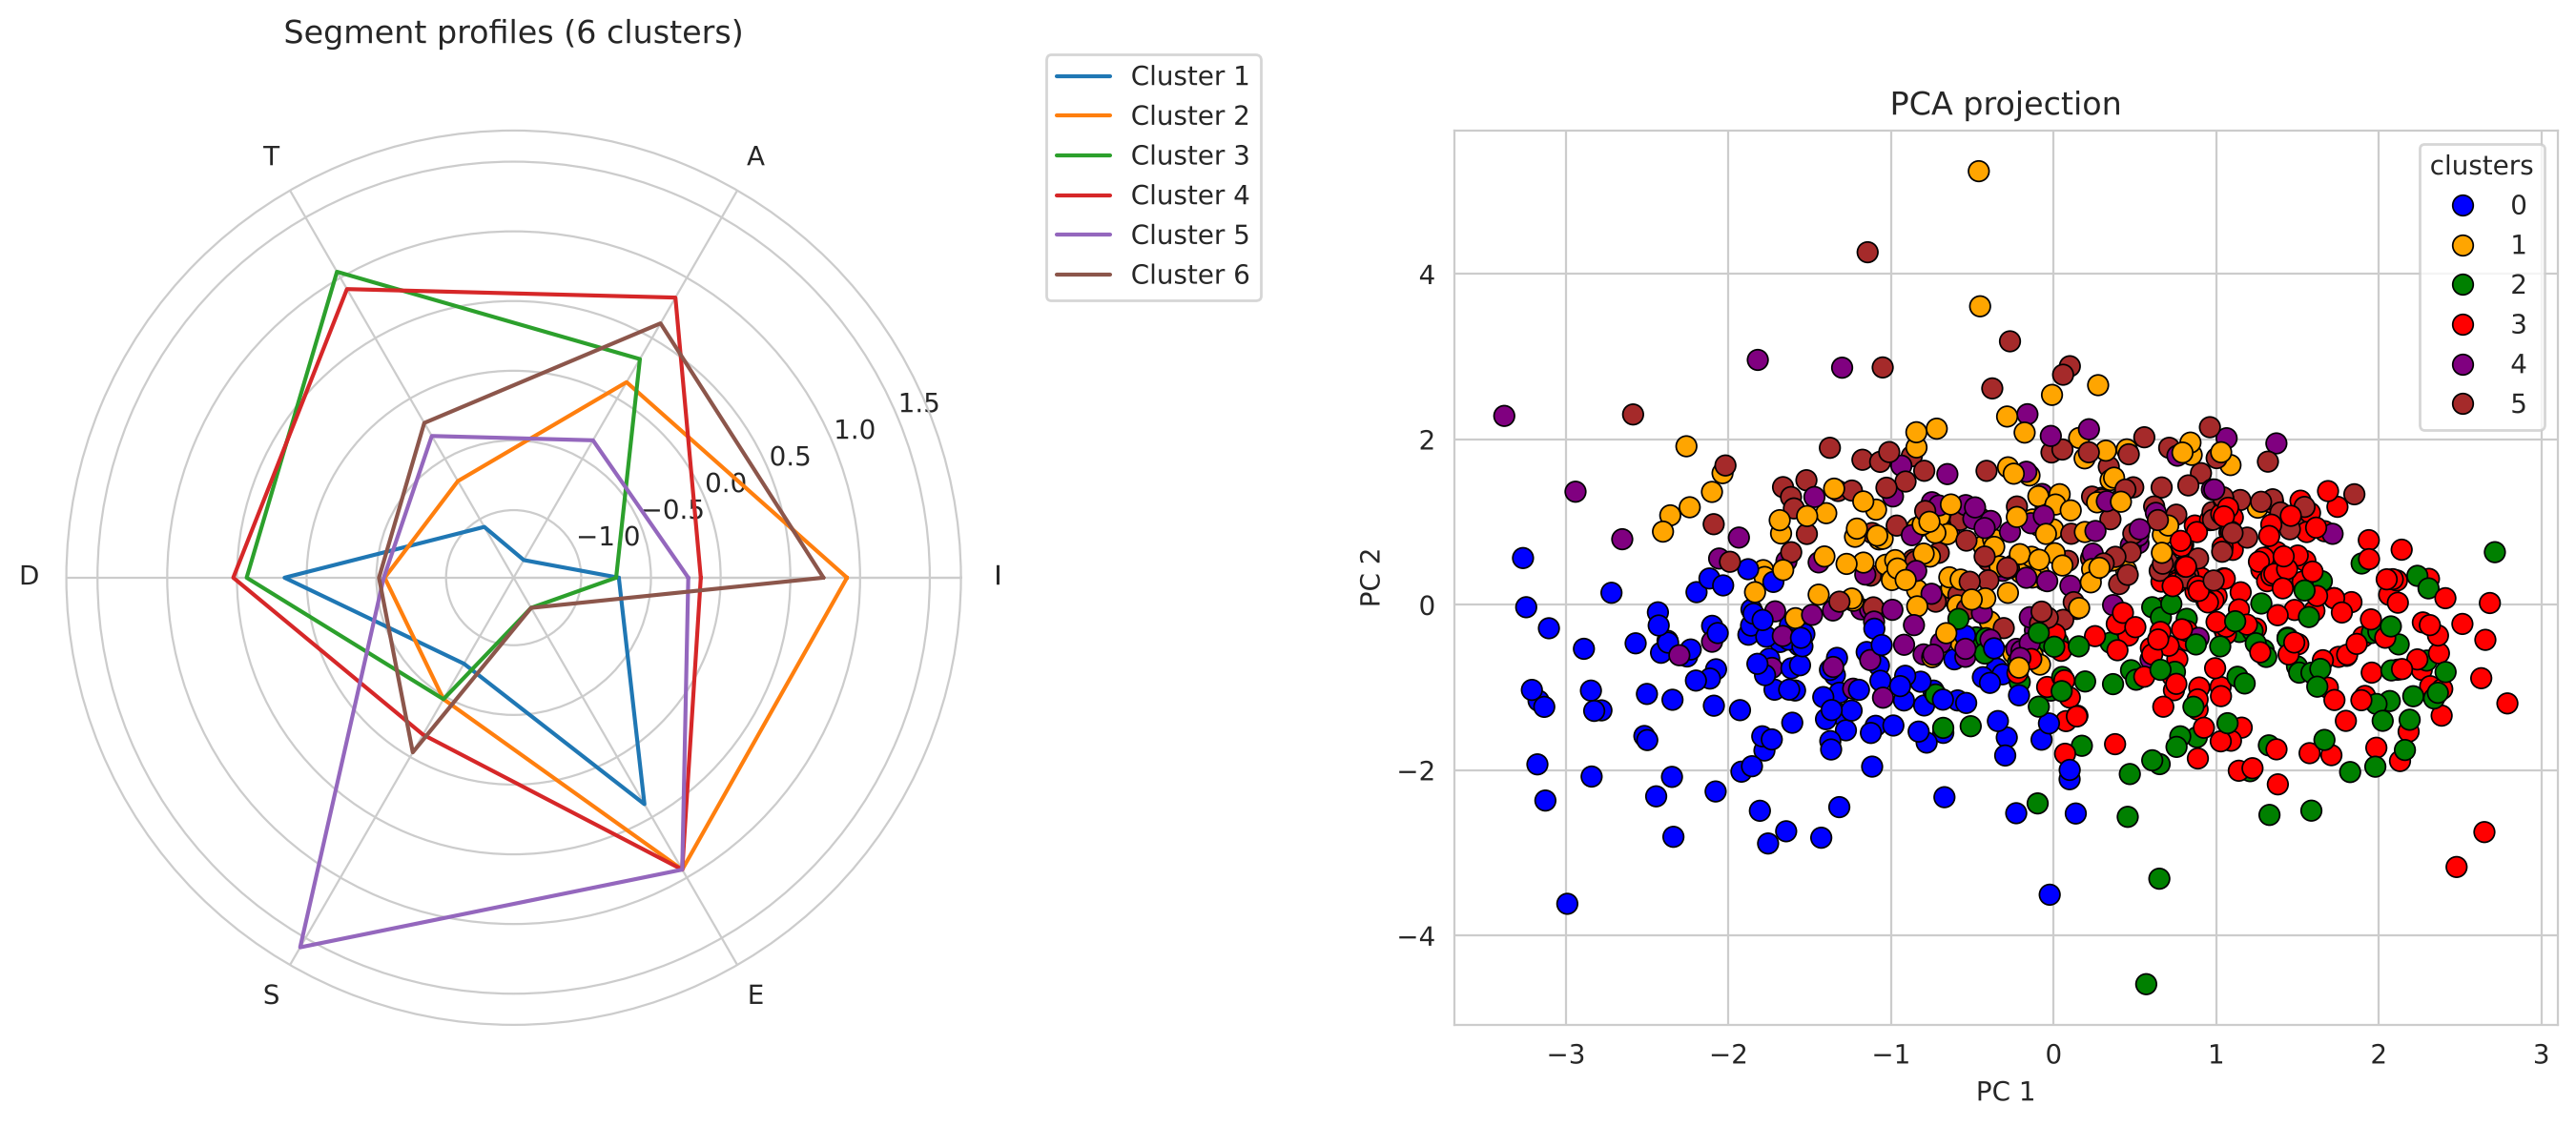

In [25]:
category = ['I','A','T','D','S','E']
label_loc = np.linspace(0, 2*np.pi, len(category)+1)
fig = plt.figure(figsize=(14,6))
ax1 = fig.add_subplot(121, polar=True)
for i in range(6):
    vals = radar_plot_6.loc[i, category].tolist(); vals.append(vals[0])
    ax1.plot(label_loc, vals, label=f'Cluster {i+1}')
ax1.set_thetagrids(np.degrees(label_loc), labels=category+[category[0]])
ax1.set_title('Segment profiles (6 clusters)', y=1.08); ax1.legend(loc='upper right', bbox_to_anchor=(1.35,1.1))

pcs = PCA(n_components=2).fit_transform(data_std_6.drop(columns='clusters'))
ax2 = fig.add_subplot(122)
sns.scatterplot(x=pcs[:,0], y=pcs[:,1], hue=data_std_6['clusters'], palette=['blue','orange','green','red','purple','brown'], edgecolor='black', s=60, ax=ax2)
ax2.set(xlabel='PC 1', ylabel='PC 2', title='PCA projection')
plt.tight_layout(); plt.show()

Comparing the three: k = 4 has no short-employment (early-career) segment, so that group gets absorbed into the over-leveraged one; k = 6 splits the early-career group into two overlapping sub-groups (see PCA) with small sizes. **k = 5 gives the most distinct and interpretable segments with reasonably balanced sizes, so we use 5 clusters.**

# **Modeling**

In [26]:
kmeans = KMeans(n_clusters=5, random_state=0, n_init=10).fit(data_std)
data_std['clusters'] = kmeans.labels_
radar_plot = data_std.groupby('clusters').agg('median').reset_index()
radar_plot

,clusters,I,A,T,D,S,E
0,0,-0.562918,-1.202368,-0.987118,0.286847,-0.625050,0.391680
1,1,1.011893,0.233936,-0.684579,-0.741676,-0.404793,0.662698
2,2,-0.084140,0.841991,0.924582,0.515272,-0.184536,0.933716
3,3,-0.069931,-0.210091,-0.372534,-0.673271,1.577523,0.391680
4,4,-0.232172,0.622343,0.607632,0.165306,-0.331374,-1.234430


explained variance: [0.292 0.234]


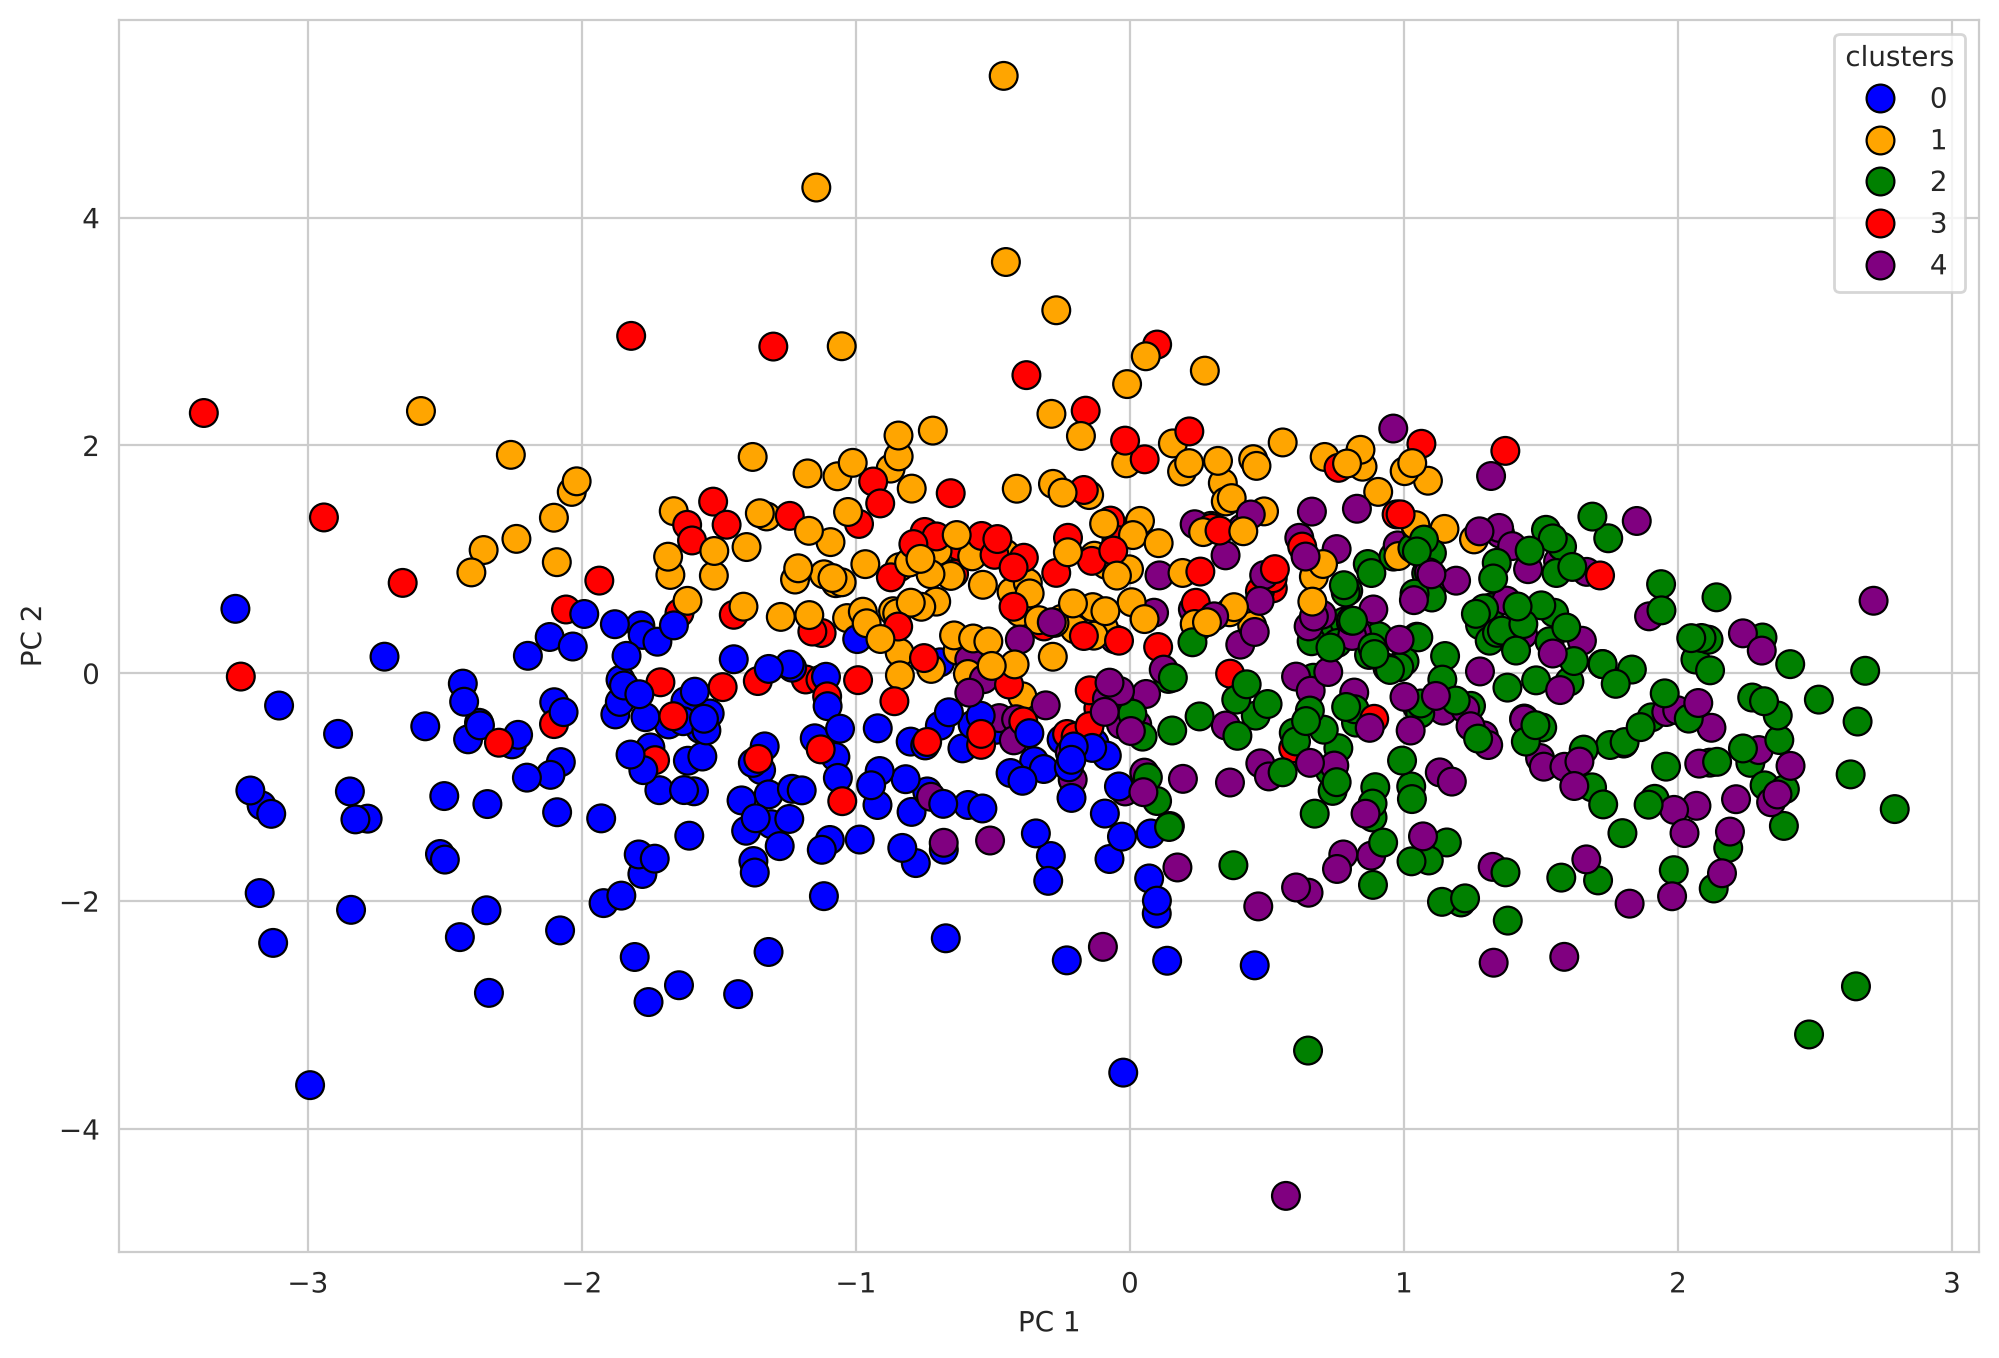

In [27]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(data_std.drop(columns='clusters'))
print('explained variance:', pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(figsize=(12,8))
sns.scatterplot(x=pcs[:,0], y=pcs[:,1], hue=data_std['clusters'], edgecolor='black',
                palette=['blue','orange','green','red','purple'], s=100, ax=ax)
ax.set(xlabel='PC 1', ylabel='PC 2'); plt.show()

# **Segment** **Profiling** (original units)

In [28]:
prof = data.copy(); prof['clusters'] = kmeans.labels_
summary = prof.groupby('clusters').agg(
    loans=('Default','size'),
    income_med=('revenue','median'),
    loan_amt_med=('loan_amnt','median'),
    lti_med=('lti','median'),
    dti_med=('dti_n','median'),
    fico_med=('fico_n','median'),
    emp_yrs_med=('emp_years','median'),
    default_rate=('Default','mean'),
).round(3)
summary['share_%'] = (summary['loans']/summary['loans'].sum()*100).round(1)
summary['defaults'] = prof.groupby('clusters')['Default'].sum()
summary

,loans,income_med,loan_amt_med,lti_med,dti_med,fico_med,emp_yrs_med,default_rate,share_%,defaults
clusters,,,,,,,,,,
0,160,60000.0,5500.0,0.091,21.275,682.0,8.0,0.131,22.2,21
1,148,125000.0,15000.0,0.121,12.855,689.5,9.0,0.074,20.5,11
2,170,75000.0,22937.5,0.298,23.145,697.0,10.0,0.194,23.6,33
3,98,75500.0,11000.0,0.154,13.415,757.0,8.0,0.031,13.6,3
4,145,70000.0,19675.0,0.261,20.280,692.0,2.0,0.179,20.1,26


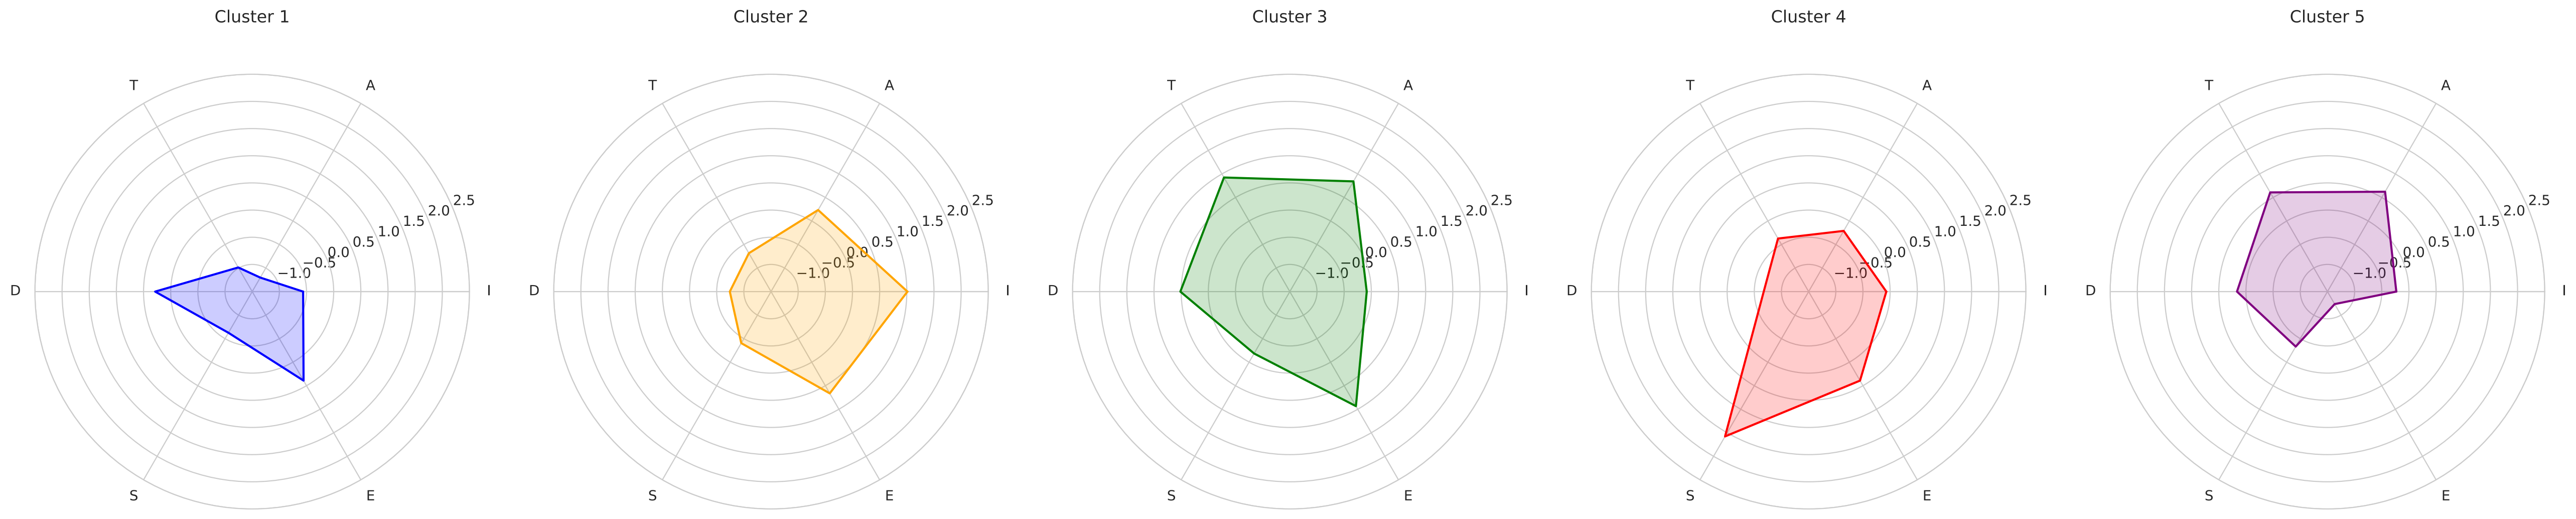

In [29]:
category = ['I','A','T','D','S','E']
color = ['blue','orange','green','red','purple']
label_loc = np.linspace(0, 2*np.pi, len(category)+1)
fig, axes = plt.subplots(1, 5, figsize=(26,5), subplot_kw=dict(polar=True))
for i, ax in enumerate(axes):
    vals = radar_plot.loc[i, category].tolist(); vals.append(vals[0])
    ax.plot(label_loc, vals, color=color[i]); ax.fill(label_loc, vals, color=color[i], alpha=0.2)
    ax.set_thetagrids(np.degrees(label_loc), labels=category+[category[0]])
    ax.set_ylim(-1.5, 2.5); ax.set_title(f'Cluster {i+1}', y=1.1)
plt.tight_layout(); plt.show()

# **Segment** **Naming**
Segments are named from their profile with rules (not by hard-coded cluster ids) so the labels stay correct if the cluster numbering changes.

In [30]:
med = prof.groupby('clusters')[['revenue','loan_amnt','lti','dti_n','fico_n','emp_years']].median()
names, left = {}, set(med.index)
def assign(label, series, largest=True):
    c = (series[list(left)].idxmax() if largest else series[list(left)].idxmin())
    names[c] = label; left.remove(c)

assign('Prime Low-Risk Borrowers',        med['fico_n'])            # best credit score
assign('Affluent Conservative Borrowers', med['revenue'])           # highest income
assign('Over-Leveraged Borrowers',        med['lti'])               # largest loan relative to income
assign('Thin-File Early-Career Borrowers',med['emp_years'], False)  # shortest employment
assign('Small-Ticket Lower-Income Borrowers', med['revenue'], False)
prof['segment'] = prof['clusters'].map(names)
data_std['segment'] = data_std['clusters'].map(names)
{int(k):v for k,v in names.items()}

{3: 'Prime Low-Risk Borrowers',
 1: 'Affluent Conservative Borrowers',
 2: 'Over-Leveraged Borrowers',
 4: 'Thin-File Early-Career Borrowers',
 0: 'Small-Ticket Lower-Income Borrowers'}

# **Risk** **Pattern** **Analysis**

In [31]:
risk = prof.groupby('segment').agg(
    loans=('Default','size'), defaults=('Default','sum'), default_rate=('Default','mean'),
    exposure=('loan_amnt','sum'), defaulted_exposure=('loan_amnt', lambda s: s[prof.loc[s.index,'Default']==1].sum()),
).round(3)
overall = prof['Default'].mean()
risk['exposure_share_%']  = (risk['exposure']/risk['exposure'].sum()*100).round(1)
risk['default_$_share_%'] = (risk['defaulted_exposure']/risk['defaulted_exposure'].sum()*100).round(1)
risk['risk_index'] = (risk['default_rate']/overall).round(2)   # 1.0 = portfolio average
risk = risk.sort_values('default_rate', ascending=False)
print('Portfolio default rate:', round(overall,4))
risk

Portfolio default rate: 0.1304


,loans,defaults,default_rate,exposure,defaulted_exposure,exposure_share_%,default_$_share_%,risk_index
segment,,,,,,,,
Over-Leveraged Borrowers,170,33,0.194,3826425,755425,34.0,45.7,1.49
Thin-File Early-Career Borrowers,145,26,0.179,2844225,532625,25.2,32.2,1.37
Small-Ticket Lower-Income Borrowers,160,21,0.131,933050,141075,8.3,8.5,1.00
Affluent Conservative Borrowers,148,11,0.074,2516975,171200,22.3,10.4,0.57
Prime Low-Risk Borrowers,98,3,0.031,1150025,52675,10.2,3.2,0.24


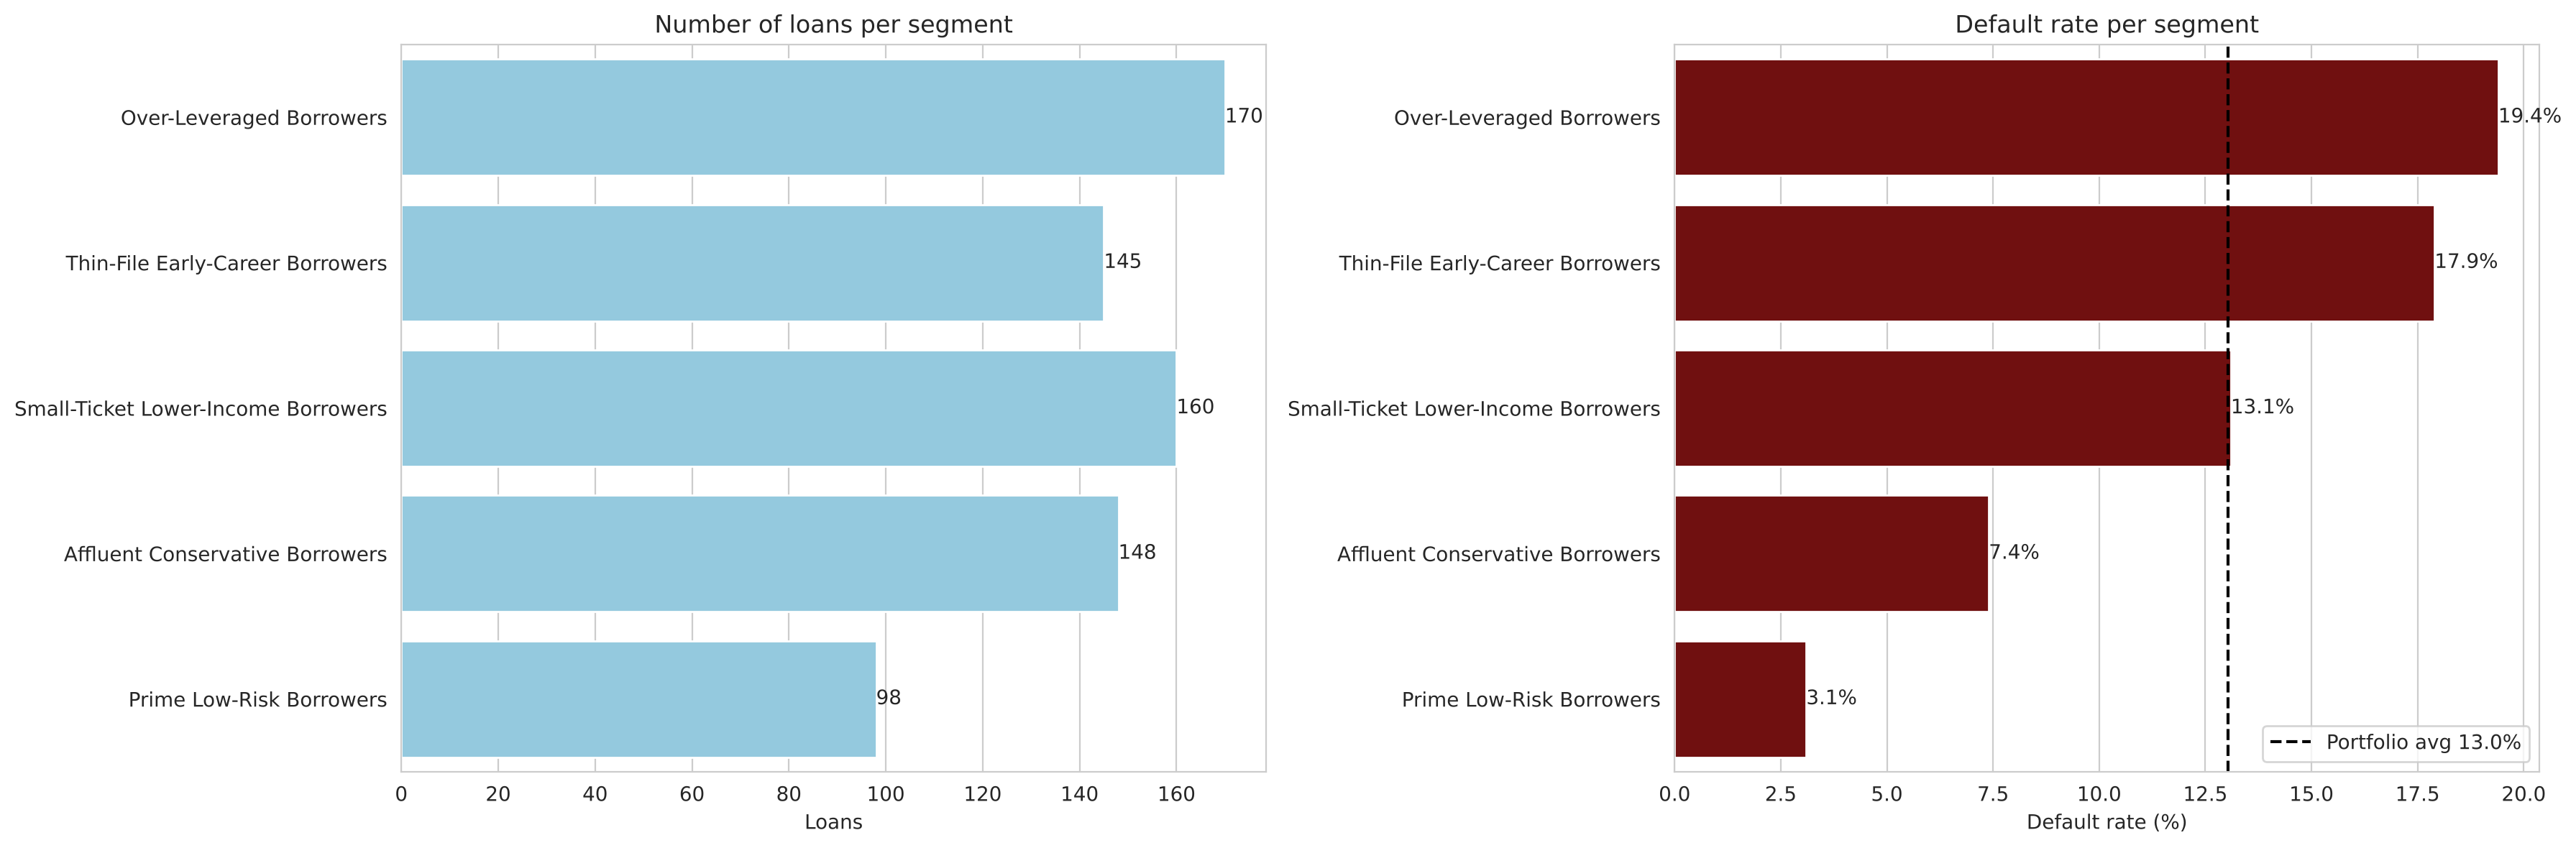

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(18,6))
order = risk.index
sns.countplot(y='segment', data=prof, order=order, color='skyblue', ax=ax[0])
ax[0].bar_label(ax[0].containers[0]); ax[0].set(title='Number of loans per segment', xlabel='Loans', ylabel='')
sns.barplot(x=risk['default_rate']*100, y=order, color='#800000', ax=ax[1])
ax[1].axvline(overall*100, color='black', linestyle='--', label=f'Portfolio avg {overall*100:.1f}%')
ax[1].bar_label(ax[1].containers[0], fmt='%.1f%%'); ax[1].legend()
ax[1].set(title='Default rate per segment', xlabel='Default rate (%)', ylabel='')
plt.tight_layout(); plt.show()

In [33]:
# Which borrower attributes separate defaulters from non-defaulters? (supports the segment story)
cmp = prof.groupby('Default')[['revenue','loan_amnt','lti','dti_n','fico_n','emp_years']].median().T
cmp.columns = ['Non-default','Default']; cmp['diff_%'] = ((cmp['Default']/cmp['Non-default']-1)*100).round(1)
cmp

,Non-default,Default,diff_%
revenue,80000.000000,73000.000000,-8.8
loan_amnt,13750.000000,17675.000000,28.5
lti,0.179688,0.237403,32.1
dti_n,17.710000,22.075000,24.6
fico_n,697.000000,687.000000,-1.4
emp_years,8.000000,8.000000,0.0


In [34]:
# Default rate by loan purpose and by FICO band
print((prof.groupby('purpose')['Default'].agg(['size','mean']).query('size>=30')
       .rename(columns={'size':'loans','mean':'default_rate'}).round(3)), '\n')
prof['fico_band'] = pd.cut(prof['fico_n'], [0,680,700,720,750,900], labels=['<680','680-699','700-719','720-749','750+'])
print(prof.groupby('fico_band', observed=True)['Default'].agg(['size','mean']).rename(columns={'size':'loans','mean':'default_rate'}).round(3))

                    loans  default_rate
purpose                                
credit_card           174         0.109
debt_consolidation    409         0.147
home_improvement       67         0.134
other                  33         0.030 

           loans  default_rate
fico_band                     
<680         213         0.174
680-699      176         0.153
700-719      142         0.134
720-749      119         0.084
750+          71         0.014


# **Conclusion**
Based on the IATDSE model, we get 5 borrower segments (default rate in brackets; portfolio average 13.0%):
1. **Over-Leveraged Borrowers** – 170 loans, 34% of exposure, **19.4%** default, 1.49x average. Largest loans relative to income (median LTI ~0.30) and highest DTI (~23). They produce ~46% of defaulted dollars. **Action:** tighter LTI/DTI caps, smaller limits, closer monitoring.
2. **Thin-File Early-Career Borrowers** – 145 loans, **17.9%** default. Median 2 years of employment, high loan size. **Action:** income verification, step-up limits.
3. **Small-Ticket Lower-Income Borrowers** – 160 loans, 13.1% default (= portfolio average) but only 8% of exposure. Low loss severity; keep, but watch weak credit scores (median FICO 682).
4. **Affluent Conservative Borrowers** – 148 loans, **7.4%** default. High income, low DTI (~13). **Action:** growth / cross-sell target.
5. **Prime Low-Risk Borrowers** – 98 loans, **3.1%** default (3 defaults). Median FICO 757. **Action:** best candidates for lower pricing and retention offers.

**Risk patterns.** Defaulted loans are larger (+29%), more leveraged vs income (LTI +32%) and carry higher DTI (+25%) than performing loans, while income and employment alone separate them little. Default rate falls steeply with FICO (17.4% below 680 vs 1.4% at 750+). The highest-risk segments are defined by *leverage*, not by income, so affordability metrics (LTI, DTI) matter as much as the bureau score.

**Caveats.** Only 721 loans and 94 defaults, so segment default rates (especially Prime: 3 defaults) carry wide uncertainty. Silhouette is low (~0.18), meaning segments overlap and should be read as risk tiers on a continuum rather than hard groups. `Default` was not a clustering input, so the risk separation above is an independent validation. Re-run with more data before using for credit policy.

In [35]:
# Export the scored portfolio
out = pd.read_excel('portfolio.xlsx')
out['cluster'] = kmeans.labels_ + 1
out['segment'] = prof['segment'].values
out.to_excel('portfolio_segmented.xlsx', index=False)
risk.to_excel('segment_risk_summary.xlsx')
out[['id','cluster','segment','Default']].head()

,id,cluster,segment,Default
0,68407277,1,Small-Ticket Lower-Income Borrowers,0
1,68355089,3,Over-Leveraged Borrowers,0
2,68341763,3,Over-Leveraged Borrowers,0
3,68476807,1,Small-Ticket Lower-Income Borrowers,0
4,68476668,2,Affluent Conservative Borrowers,0
